In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
IMAGE_DIR = "/tmp/bshi/plantnet/"
META_DIR = "../data/plantnet/"

In [3]:
species_metadata = pd.read_csv(IMAGE_DIR + "species_metadata.csv")
species_metadata["genus_id"] = pd.factorize(species_metadata['genus'])[0]
species_metadata.to_csv(IMAGE_DIR + "species_genus_metadata.csv")
geo_time = pd.read_csv(META_DIR + "plantnet_geo_time.csv")
merged = geo_time.merge(species_metadata, on="species_id", how="left", validate="many_to_one")

In [4]:
species_sizes = merged.groupby(["species_id"]).size()
genus_sizes = merged.groupby(["genus_id"]).size()
species_per_genus = merged.groupby(["genus_id"])["species_id"].nunique()

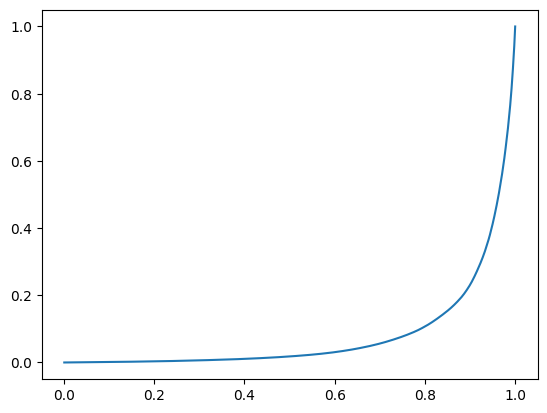

In [5]:
sorted_species_sizes = species_sizes.sort_values(ascending=True)
total = sum(species_sizes)
xs = np.array(range(len(species_sizes))) + 1
ys = []
count = 0
for i in range(len(species_sizes)):
    count += sorted_species_sizes.iloc[i]
    ys.append(count)
xs = xs / len(species_sizes)
ys = np.array(ys) / total
plt.plot(xs, ys)

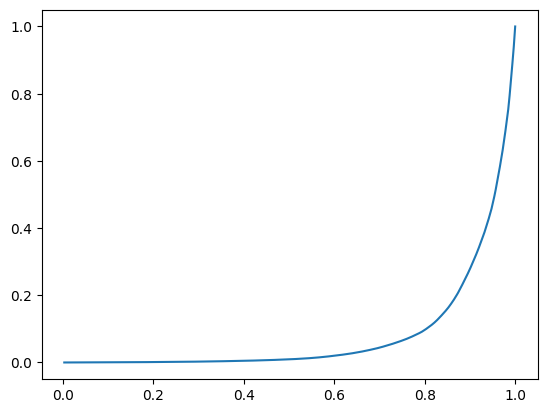

In [6]:
sorted_genus_sizes = genus_sizes.sort_values(ascending=True)
total = sum(genus_sizes)
xs = np.array(range(len(genus_sizes))) + 1
ys = []
count = 0
for i in range(len(genus_sizes)):
    count += sorted_genus_sizes.iloc[i]
    ys.append(count)
xs = xs / len(genus_sizes)
ys = np.array(ys) / total
plt.plot(xs, ys)

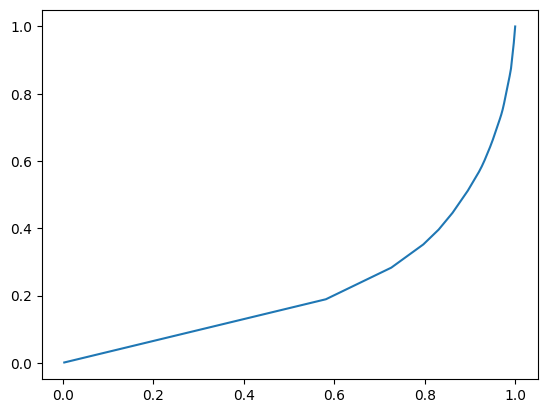

In [7]:
sorted_species_per_genus = species_per_genus.sort_values(ascending=True)
total = sum(species_per_genus)
xs = np.array(range(len(species_per_genus))) + 1
ys = []
count = 0
for i in range(len(species_per_genus)):
    count += sorted_species_per_genus.iloc[i]
    ys.append(count)
xs = xs / len(species_per_genus)
ys = np.array(ys) / total
plt.plot(xs, ys)

In [8]:
total = sum(merged.groupby(["split"]).size())
merged.groupby(["split"]).size() / total

split
test     0.101625
train    0.796721
val      0.101654
dtype: float64

In [9]:
def split_keep_singletons(idx, y, test_ratio, seed=0):
    """Stratified split; labels with a single sample always go to the first (train) set."""
    idx, y = np.asarray(idx), np.asarray(y)
    ok = pd.Series(y).map(pd.Series(y).value_counts()).to_numpy() >= 2   # label has >= 2 samples
    n_test = int(np.ceil(test_ratio * len(idx)))     # integer count so the total stays exact
    tr, te = train_test_split(idx[ok], test_size=n_test, random_state=seed, stratify=y[ok])
    return np.concatenate([tr, idx[~ok]]), te

### Predict genus, but remove certain species from genus

In [10]:
test_ratio = 0.2

seed = 0
rng = np.random.default_rng(seed)

sp_counts = (
    merged.groupby(["genus_id", "species_id"]).size()
    .rename("n_images").reset_index()
    .sort_values(["genus_id", "n_images", "species_id"])   # smallest species first; species_id breaks ties
)
sp_counts["genus_total"] = sp_counts.groupby("genus_id")["n_images"].transform("sum")
sp_counts["cum_images"] = sp_counts.groupby("genus_id")["n_images"].cumsum()
sp_counts["is_test"] = sp_counts["cum_images"] <= test_ratio * sp_counts["genus_total"]
test_species = set(sp_counts.loc[sp_counts["is_test"], "species_id"])
merged["genus_split"] = np.where(merged["species_id"].isin(test_species), "test", "train")

for g, gdf in merged.groupby("genus_id"):
    need = int(np.ceil(test_ratio * len(gdf))) - (gdf["genus_split"] == "test").sum()
    if need <= 0:
        continue
    remaining = sp_counts[(sp_counts["genus_id"] == g) & ~sp_counts["is_test"]]   # already smallest first
    for sid, n in zip(remaining["species_id"], remaining["n_images"]):
        if need <= 0:
            break
        idx = gdf.index[gdf["species_id"] == sid]
        chosen = rng.choice(idx, size=min(need, n), replace=False)
        merged.loc[chosen, "genus_split"] = "test"
        need -= len(chosen)


total = sum(merged.groupby(["genus_split"]).size())
train_pos = np.flatnonzero(merged["genus_split"] == "train")
val_ratio = 0.2 / (merged.groupby(["genus_split"]).size() / total)["train"]
val_inds = train_test_split(train_pos, test_size=val_ratio, random_state=seed, stratify=merged["genus_id"][train_pos])[1]
merged.loc[val_inds, "genus_split"] = "val"

In [11]:
total = sum(merged.groupby(["genus_split"]).size())
merged.groupby(["genus_split"]).size() / total

genus_split
test     0.200391
train    0.599607
val      0.200002
dtype: float64

### Use geolocation data -- smallest countries in test, 0.6/0.2/0.2 split

In [12]:
has_geo = merged["lat"].notna() & merged["lon"].notna()
pts = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(merged.loc[has_geo, "lon"], merged.loc[has_geo, "lat"]),
    index=merged.index[has_geo],
    crs="EPSG:4326",
)

world = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_countries.zip"
)[["ADMIN", "geometry"]]

j = gpd.sjoin(pts, world, how="left", predicate="within")
j = j[~j.index.duplicated(keep="first")]        # a point on a border can match two polygons
                 # aligned on index; stays NaN where lat/lon is missing
merged["country"] = j["ADMIN"]

In [13]:
test_ratio = 0.2
seed = 0

merged_w_countries = merged[merged["country"].notna()]
test_num = test_ratio * len(merged_w_countries)   
total = merged_w_countries.groupby("species_id").size()  
ct = pd.crosstab(merged_w_countries["species_id"], merged_w_countries["country"]) 
test_cnt = pd.Series(0, index=total.index)

chosen, used = [], 0
for c in ct.sum().sort_values().index:          # countries by image count, smallest first
    n = int(ct[c].sum())
    if used + n > test_num:
        break                                   # later countries are bigger, so they won't fit either
    new = test_cnt + ct[c]
    if (new >= total).any():                    # would leave some species with no train image
        continue
    test_cnt, used = new, used + n
    chosen.append(c)


rng = np.random.default_rng(seed)
need = int(np.ceil(test_ratio * len(merged_w_countries))) - used            # test images still missing

trainpool = merged_w_countries[~merged_w_countries["country"].isin(chosen)]        # located images not in a test country
reserved = trainpool.groupby("species_id").sample(1, random_state=0)   # 1 image per species stays in train
pool = trainpool.drop(reserved.index)

extra = []
for c in trainpool.groupby("country").size().sort_values().index:      # smallest remaining countries first
    if need <= 0:
        break
    idx = pool.index[pool["country"] == c]
    take = rng.choice(idx, size=min(need, len(idx)), replace=False)
    extra.extend(take)
    need -= len(take)
assert need <= 0, "not enough images to reach the test quota"

merged["country_split"] = np.nan
merged.loc[merged_w_countries.index, "country_split"] = "train"
merged.loc[merged_w_countries.index[merged_w_countries["country"].isin(chosen)], "country_split"] = "test"
merged.loc[extra, "country_split"] = "test"

total = sum(merged.groupby(["country_split"]).size())
train_pos = np.flatnonzero(merged["country_split"] == "train")
val_ratio = 0.2 / (merged.groupby(["country_split"]).size() / total)["train"]
val_inds = split_keep_singletons(train_pos, merged["species_id"][train_pos], test_ratio=val_ratio, seed=seed)[1]
merged.loc[val_inds, "country_split"] = "val"

/tmp/ipykernel_1732053/866416445.py:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'train' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  merged.loc[merged_w_countries.index, "country_split"] = "train"


In [14]:
merged[merged["country"].notna()].groupby(["country_split"]).size() / sum(merged[merged["country"].notna()].groupby(["country_split"]).size())

country_split
test     0.200002
train    0.599997
val      0.200002
dtype: float64

### Use geolocation data -- France is train/val, 1/3 of train is in val

In [15]:
merged["country_split_hard"] = np.nan                                  # no country -> stays NaN
has_country = merged["country"].notna() & (merged["country"] != "-99")
merged.loc[has_country & (merged["country"] == "France"), "country_split_hard"] = "train"
merged.loc[has_country & (merged["country"] != "France"), "country_split_hard"] = "test"

# test species with no train image: move the earliest image of each into train
train_species = set(merged.loc[merged["country_split_hard"] == "train", "species_id"])
orphans = merged[(merged["country_split_hard"] == "test") & ~merged["species_id"].isin(train_species)]
moved = orphans.sort_values("date", kind="stable").groupby("species_id").head(1).index
merged.loc[moved, "country_split_hard"] = "train"

total = sum(merged.groupby(["country_split_hard"]).size())
train_pos = np.flatnonzero(merged["country_split_hard"] == "train")
val_ratio = 1/4
val_inds = split_keep_singletons(train_pos, merged["species_id"][train_pos], test_ratio=val_ratio, seed=seed)[1]
merged.loc[val_inds, "country_split_hard"] = "val"

/tmp/ipykernel_1732053/2789364042.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'train' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  merged.loc[has_country & (merged["country"] == "France"), "country_split_hard"] = "train"


In [16]:
merged[merged["country"].notna()].groupby(["country_split_hard"]).size() / sum(merged[merged["country"].notna()].groupby(["country_split_hard"]).size())

country_split_hard
test     0.695481
train    0.228389
val      0.076130
dtype: float64

### Use time data -- latest dates in test, 0.6/0.2/0.2 split, by date

/tmp/ipykernel_1732053/3362536123.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  date_after_2010["date"] = pd.to_datetime(date_after_2010["date"], errors="coerce")


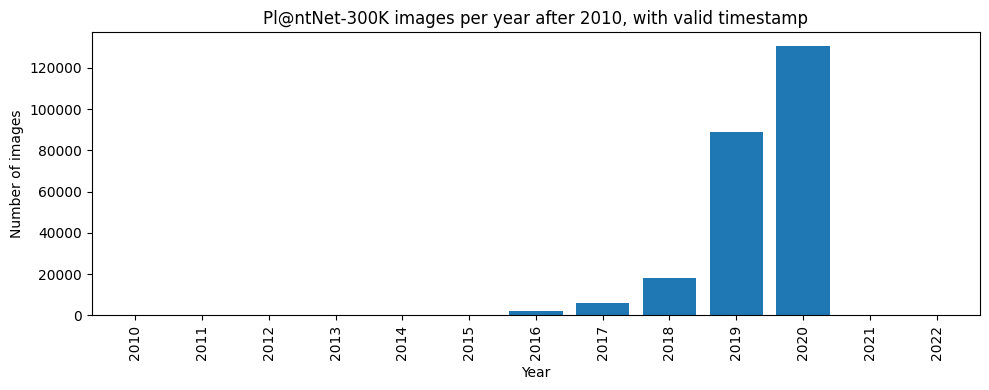

In [17]:
date_after_2010 = merged.loc[(merged["date"].notna()) & (merged["date"] >= "2010-01-01"), :]
date_after_2010["date"] = pd.to_datetime(date_after_2010["date"], errors="coerce")
counts = date_after_2010["date"].dt.year.value_counts().sort_index()
counts.index = counts.index.astype(int)

ax = counts.plot.bar(figsize=(10, 4), width=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("Number of images")
ax.set_title("Pl@ntNet-300K images per year after 2010, with valid timestamp")
plt.tight_layout()
plt.show()

In [18]:
dated = merged[merged["date"].notna()].sort_values("date", kind="stable")
n_train = int(round(0.80 * len(dated)))

merged["date_split"] = np.nan                                # no date -> stays NaN
merged.loc[dated.index[:n_train], "date_split"] = "train"    # earliest 80%
merged.loc[dated.index[n_train:], "date_split"] = "test"     # latest 20%

# test species with no train image: move the earliest image of each into train
train_species = set(merged.loc[merged["date_split"] == "train", "species_id"])
orphans = merged[(merged["date_split"] == "test") & ~merged["species_id"].isin(train_species)]
moved = orphans.sort_values("date", kind="stable").groupby("species_id").head(1).index
merged.loc[moved, "date_split"] = "train"

train = merged[merged["date_split"] == "train"]
val_ratio = 0.25
n_val = int(np.ceil(val_ratio * len(train)))

reserved = train.sort_values("date", kind="stable").groupby("species_id").head(1).index   # earliest image per species stays in train
pool = train.drop(reserved)
val_idx = pool.sort_values("date", ascending=False, kind="stable").head(n_val).index      # latest dates first

merged.loc[val_idx, "date_split"] = "val"

/tmp/ipykernel_1732053/3973780037.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'train' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  merged.loc[dated.index[:n_train], "date_split"] = "train"    # earliest 80%


In [19]:
merged[merged["date"].notna()].groupby(["date_split"]).size() / sum(merged[merged["date"].notna()].groupby(["date_split"]).size())

date_split
test     0.199964
train    0.600024
val      0.200012
dtype: float64

### Use time data -- test set 2020 and later

In [20]:
merged["date_split_hard"] = np.nan                                   # images with no date stay NaN
merged.loc[merged["date"] < "2020-01-01", "date_split_hard"] = "train"
merged.loc[merged["date"] >= "2020-01-01", "date_split_hard"] = "test"

# test species with no train image: move the earliest image of each into train
train_species = set(merged.loc[merged["date_split_hard"] == "train", "species_id"])
orphans = merged[(merged["date_split_hard"] == "test") & ~merged["species_id"].isin(train_species)]
earliest = orphans.sort_values("date", kind="stable").groupby("species_id").head(1).index
merged.loc[earliest, "date_split_hard"] = "train"

train = merged[merged["date_split_hard"] == "train"]
val_ratio = 0.25
n_val = int(np.ceil(val_ratio * len(train)))

reserved = train.sort_values("date", kind="stable").groupby("species_id").head(1).index   # earliest image per species stays in train
pool = train.drop(reserved)
val_idx = pool.sort_values("date", ascending=False, kind="stable").head(n_val).index      # latest dates first

merged.loc[val_idx, "date_split_hard"] = "val"

/tmp/ipykernel_1732053/3946506753.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'train' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  merged.loc[merged["date"] < "2020-01-01", "date_split_hard"] = "train"


In [21]:
merged[merged["date"].notna()].groupby(["date_split_hard"]).size() / sum(merged[merged["date"].notna()].groupby(["date_split_hard"]).size())

date_split_hard
test     0.528118
train    0.353910
val      0.117973
dtype: float64

### Write CSV

In [22]:
merged = merged[["PN_hash", "PN_observation_id", "species_id", "species", "genus_id", "genus", "country", "date", "split", "genus_split", "country_split", "country_split_hard", "date_split", "date_split_hard"]]
merged = merged.rename(columns={"split": "original_split"})


merged.to_csv(META_DIR + "plantnet_geo_final.csv")

In [23]:
merged.columns

Index(['PN_hash', 'PN_observation_id', 'species_id', 'species', 'genus_id',
       'genus', 'country', 'date', 'original_split', 'genus_split',
       'country_split', 'country_split_hard', 'date_split', 'date_split_hard'],
      dtype='object')